In [1]:
import numpy as np
import time
from datetime import timedelta
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Flatten, Dense, Dropout, Input, BatchNormalization, GlobalAveragePooling1D
from keras.optimizers import Adam

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.regularizers import l2

from tensorflow.keras.layers import LSTM

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#from google.colab import drive
#drive.mount('/content/drive')

# Data shtuff

In [3]:
path = r"with duplicates\combined.csv"
df = pd.read_csv(path)

In [4]:
display(df)

,2,3,4,5,6,7,8,9,10,11,...,35,36,37,38,39,40,41,42,43,target
0,1,1,0,1,27,-1.398295,4.552336,8.461134,9.709263,-1.573943,...,-0.300669,0.918815,0.174533,1.015117,33.908630,-28.277462,-9.235774,45.107754,14.0,0
1,1,1,0,1,27,-1.593871,4.467315,8.753821,9.956240,-1.543731,...,-0.303881,0.919232,0.174533,1.015117,33.908630,-28.277462,-9.235774,45.107754,14.0,0
2,1,1,0,1,27,-1.593871,4.467315,8.753821,9.956240,-1.543731,...,-0.303881,0.919232,0.174533,1.015117,34.351746,-27.661564,-9.056985,45.024810,14.0,0
3,1,2,0,1,27,-1.669115,4.492037,8.941505,10.144695,-1.528073,...,-0.303881,0.919232,0.174533,1.015117,34.698883,-27.327988,-8.964363,45.068737,14.0,0
4,1,2,0,1,27,-1.669115,4.492037,8.941505,10.144695,-1.528073,...,-0.303881,0.919232,0.174533,1.015117,34.698883,-27.327988,-8.964363,45.068737,14.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1540367,1,74,4,7,67,0.114925,8.008849,5.528380,9.732310,-0.005215,...,0.596749,0.658655,0.000000,0.999999,275.657600,-54.558193,-0.037395,281.004820,0.0,1
1540368,1,74,4,7,67,0.134079,8.157294,5.676825,9.939103,0.011862,...,0.596476,0.659024,0.000000,0.999999,275.678400,-54.535530,0.085088,281.020840,0.0,1
1540369,1,74,4,7,67,0.134079,8.157294,5.676825,9.939103,0.011862,...,0.596476,0.659024,0.000000,0.999999,275.678400,-54.535530,0.085088,281.020840,0.0,1
1540370,1,74,4,7,67,0.134079,8.157294,5.676825,9.939103,0.011862,...,0.596476,0.659024,0.000000,0.999999,275.678400,-54.535530,0.085088,281.020840,0.0,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1540372 entries, 0 to 1540371
Data columns (total 43 columns):
 #   Column  Non-Null Count    Dtype  
---  ------  --------------    -----  
 0   2       1540372 non-null  int64  
 1   3       1540372 non-null  int64  
 2   4       1540372 non-null  int64  
 3   5       1540372 non-null  int64  
 4   6       1540372 non-null  int64  
 5   7       1540372 non-null  float64
 6   8       1540372 non-null  float64
 7   9       1540372 non-null  float64
 8   10      1540372 non-null  float64
 9   11      1540372 non-null  float64
 10  12      1540372 non-null  float64
 11  13      1540372 non-null  float64
 12  14      1540372 non-null  float64
 13  15      1540372 non-null  float64
 14  16      1540372 non-null  float64
 15  17      1540372 non-null  float64
 16  18      1540372 non-null  float64
 17  19      1540372 non-null  float64
 18  20      1540372 non-null  float64
 19  21      1540372 non-null  float64
 20  22      1540372 non-null

In [6]:
df.describe()

,2,3,4,5,6,7,8,9,10,11,...,35,36,37,38,39,40,41,42,43,target
count,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,...,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06,1.540372e+06
mean,7.983857e-01,4.707580e+01,3.286836e+00,3.885590e+00,8.653627e+01,1.977982e-01,5.573672e+00,7.682127e+00,9.760306e+00,2.022103e-01,...,3.488414e-01,6.075523e-01,9.522276e+00,1.042680e+01,2.195595e+02,-3.577223e+01,1.225472e+00,2.246653e+02,7.945585e+03,5.427085e-01
std,4.012058e-01,3.576483e+01,4.673722e+00,1.617481e+00,3.707256e+01,8.467127e-01,1.725763e+00,1.492518e+00,8.827490e-01,8.085506e-01,...,5.745371e-01,2.484552e-01,4.716758e+01,4.698643e+01,9.438752e+01,1.262477e+01,4.957816e+00,9.003339e+01,4.685654e+04,4.981728e-01
min,0.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,2.700000e+01,-4.316923e+01,-7.859758e+01,-2.169642e+01,0.000000e+00,-5.295604e+00,...,-9.953161e-01,0.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,-9.175099e+01,-4.293750e+01,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.000000e+00,2.000000e+01,0.000000e+00,3.000000e+00,6.600000e+01,-2.746000e-01,4.633321e+00,7.051546e+00,9.642199e+00,-2.497514e-01,...,0.000000e+00,4.780787e-01,0.000000e+00,9.999999e-01,1.791986e+02,-4.257864e+01,-1.470000e+00,1.825938e+02,0.000000e+00,0.000000e+00
50%,1.000000e+00,4.000000e+01,1.000000e+00,4.000000e+00,7.500000e+01,2.044582e-01,5.690404e+00,7.928089e+00,9.809649e+00,2.078473e-01,...,6.212310e-01,6.060769e-01,0.000000e+00,1.000000e+00,2.478000e+02,-3.564140e+01,1.326048e+00,2.501042e+02,1.400000e+01,1.000000e+00
75%,1.000000e+00,6.600000e+01,5.000000e+00,5.000000e+00,1.000000e+02,7.026387e-01,6.632455e+00,8.636935e+00,9.982859e+00,6.822453e-01,...,7.930330e-01,7.863702e-01,1.745329e-01,1.015117e+00,2.742218e+02,-2.842071e+01,4.170168e+00,2.775646e+02,2.800000e+01,1.000000e+00
max,1.000000e+00,2.400000e+02,5.100000e+01,7.000000e+00,1.680000e+02,1.082301e+01,1.914250e+01,6.627417e+01,1.080852e+02,7.924672e+00,...,9.932119e-01,1.000000e+00,2.460000e+02,2.460020e+02,3.599998e+02,1.125000e+01,8.504688e+01,3.674279e+02,5.967330e+05,1.000000e+00


In [7]:
#shapes = pd.DataFrame({
#    "DataFrame": ["original", "1 sec", "3 secs", "5 secs", "7 secs"],
#    "Shape": [df0.shape, df1.shape, df3.shape, df5.shape, df7.shape],
#    "Total Elements": [df0.shape[0] * df0.shape[1], df1.shape[0] * df1.shape[1],
#                       df3.shape[0] * df3.shape[1], df5.shape[0] * df5.shape[1],
#                       df7.shape[0] * df7.shape[1]]
#})

#display(shapes)

In [8]:
target_distribution = df['target'].value_counts(normalize=True)
print(target_distribution)

target
1    0.542709
0    0.457291
Name: proportion, dtype: float64


In [9]:
def data_splitting(df):
    X = df.drop(columns = ["target"])
    y = df["target"]

    # Standardize the data
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42, stratify = y_train)


    # Standardize the data
    #scaler = StandardScaler()
    #X_train = scaler.fit_transform(X_train)
    #X_test = scaler.transform(X_test)
    #X_val = scaler.transform(X_val)

    #print(X_train.shape, y_train.shape)
    #print(X_val.shape, y_val.shape)
    #print(X_test.shape, y_test.shape)

    shapes_df = pd.DataFrame({
        'Set': ['Training Set', 'Validation Set', 'Test Set'],
        'Features Shape': [X_train.shape, X_val.shape, X_test.shape],
        'Labels Shape': [y_train.shape, y_val.shape, y_test.shape]
                })

    display(shapes_df)

    return X_train, y_train, X_val, y_val, X_test, y_test




In [10]:
X_train, y_train, X_val, y_val, X_test, y_test = data_splitting(df)

,Set,Features Shape,Labels Shape
0,Training Set,"(1109067, 42)","(1109067,)"
1,Validation Set,"(123230, 42)","(123230,)"
2,Test Set,"(308075, 42)","(308075,)"


In [11]:
# Compute class weights
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights))
print(class_weights_dict)

{0: 1.0933942863001733, 1: 0.9213050340588138}


# Models

## FNN

In [12]:
def fnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):
    # Assuming X_train is already defined
    input_shape = X_train.shape[1]

    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)

    # Build the model
    fnn_model = Sequential()
    fnn_model.add(Input(shape=(input_shape,)))
    fnn_model.add(Dense(512, activation='relu'))
    fnn_model.add(Dropout(0.3))
    fnn_model.add(Dense(256, activation='relu'))
    fnn_model.add(Dropout(0.3))
    fnn_model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))
    fnn_model.add(Dropout(0.5))
    fnn_model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))
    fnn_model.add(Dropout(0.6))
    fnn_model.add(Dense(32, activation='relu'))
    fnn_model.add(Dropout(0.6))
    fnn_model.add(Dense(1, activation='sigmoid'))
    fnn_model.summary()

    # Compile the model
    fnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    # Train the model
    start_time_fnn = time.time()
    fnn_history = fnn_model.fit(X_train, y_train
                        ,validation_data = (X_val, y_val)
                        ,epochs = 100
                        ,batch_size = 32
                        ,callbacks = [reduce_lr, early_stopping]
                        #,class_weight = class_weights_dict
                        )
    end_time_fnn = time.time()


    # Calculate the elapsed time
    training_time_fnn = end_time_fnn - start_time_fnn
    print(f"FNN Model training time: {training_time_fnn:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_fnn)
    milliseconds = int(training_time_fnn * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")


    # Predict on test data
    fnn_y_pred_prob = fnn_model.predict(X_test)
    fnn_y_pred = (fnn_y_pred_prob > 0.5).astype(int)


    # result calculation
    cm = confusion_matrix(y_test, fnn_y_pred)
    cr = classification_report(y_test, fnn_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, fnn_y_pred).ravel()

    precision = precision_score(y_test, fnn_y_pred)
    recall = recall_score(y_test, fnn_y_pred)
    f1 = f1_score(y_test, fnn_y_pred)
    accuracy = accuracy_score(y_test, fnn_y_pred)
    specificity = tn / (tn + fp)

    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, fnn_y_pred_prob)
    roc_auc = roc_auc_score(y_test, fnn_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, fnn_y_pred_prob)
    avg_precision = average_precision_score(y_test, fnn_y_pred_prob)

    return [fnn_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [13]:
[fnn_history, fnn_cm, fnn_cr, fnn_accuracy, fnn_precision, fnn_recall,
    fnn_f1, fnn_specificity, fnn_roc_auc, fnn_avg_precision, fnn_fpr, fnn_tpr, fnn_thresholds,
    fnn_precision_vals, fnn_recall_vals, fnn_pr_thresholds] = fnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │        22,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 196,609 (768.00 KB)

 Trainable params: 196,609 (768.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 48s 1ms/step - accuracy: 0.7805 - loss: 0.4805 - val_accuracy: 0.9521 - val_loss: 0.1462 - learning_rate: 0.0010
Epoch 2/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 48s 1ms/step - accuracy: 0.9307 - loss: 0.2012 - val_accuracy: 0.9681 - val_loss: 0.1055 - learning_rate: 0.0010
Epoch 3/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 48s 1ms/step - accuracy: 0.9469 - loss: 0.1663 - val_accuracy: 0.9677 - val_loss: 0.1024 - learning_rate: 0.0010
Epoch 4/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 47s 1ms/step - accuracy: 0.9545 - loss: 0.1481 - val_accuracy: 0.9777 - val_loss: 0.0827 - learning_rate: 0.0010
Epoch 5/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 46s 1ms/step - accuracy: 0.9593 - loss: 0.1369 - val_accuracy: 0.9792 - val_loss: 0.0762 - learning_rate: 0.0010
Epoch 6/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 46s 1ms/step - accuracy: 0.9620 - loss: 0.1301 - val_accuracy: 0.9807 - val_loss: 0.0745 - learning_rate: 0.0010
Epoch 7/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 46s 1ms

## CNN

In [14]:
def cnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):
    # Reshape data for Conv1D
    cnn_X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    cnn_X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
    cnn_X_val = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))


    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)


    # Build and train the CNN model
    cnn_model = Sequential([
        Conv1D(filters=64, kernel_size=7, activation='relu', input_shape=(cnn_X_train.shape[1], 1), kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        Dropout(0.3),

        Conv1D(filters=64, kernel_size=7, activation='relu', kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        #GlobalMaxPooling1D(),
        Dropout(0.6),

        #Conv1D(filters=128, kernel_size=7, activation='relu', kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        Dropout(0.6),
        #GlobalMaxPooling1D(),

        Flatten(),
        Dense(128, activation='relu'),# kernel_regularizer=l2(0.01)),
        Dropout(0.6),
        #Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        #Dropout(0.5),
        #Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
        #Dropout(0.5),
        Dense(32, activation='relu'),# kernel_regularizer=l2(0.01)),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    cnn_model.summary()

    cnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    start_time_cnn = time.time()
    cnn_history = cnn_model.fit(cnn_X_train, y_train
                                ,validation_data=(cnn_X_val, y_val)
                                ,epochs=100
                                ,batch_size=32
                                ,callbacks=[early_stopping, reduce_lr]
                                #,class_weight = class_weights_dict
                                )
    end_time_cnn = time.time()

    # Calculate the elapsed time
    training_time_cnn = end_time_cnn - start_time_cnn
    print(f"FNN Model training time: {training_time_cnn:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_cnn)
    milliseconds = int(training_time_cnn * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")

    # Evaluate CNN model
    cnn_y_pred_prob = cnn_model.predict(cnn_X_test)
    cnn_y_pred = (cnn_y_pred_prob > 0.5).astype(int)

    # result calculation
    cm = confusion_matrix(y_test, cnn_y_pred)
    cr = classification_report(y_test, cnn_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, cnn_y_pred).ravel()

    precision = precision_score(y_test, cnn_y_pred)
    recall = recall_score(y_test, cnn_y_pred)
    f1 = f1_score(y_test, cnn_y_pred)
    accuracy = accuracy_score(y_test, cnn_y_pred)
    specificity = tn / (tn + fp)


    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, cnn_y_pred_prob)
    roc_auc = roc_auc_score(y_test, cnn_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, cnn_y_pred_prob)
    avg_precision = average_precision_score(y_test, cnn_y_pred_prob)

    return [cnn_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [15]:
#cnn model
[cnn_history, cnn_cm, cnn_cr, cnn_accuracy, cnn_precision, cnn_recall,
    cnn_f1, cnn_specificity, cnn_roc_auc, cnn_avg_precision, cnn_fpr, cnn_tpr, cnn_thresholds,
    cnn_precision_vals, cnn_recall_vals, cnn_pr_thresholds] = cnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)

c:\Users\Mallika Lather\Desktop\Stress\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 36, 64)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 36, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 30, 64)         │        28,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       245,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 279,297 (1.07 MB)

 Trainable params: 279,297 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 81s 2ms/step - accuracy: 0.6512 - loss: 0.6051 - val_accuracy: 0.7309 - val_loss: 0.5082 - learning_rate: 0.0010
Epoch 2/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 79s 2ms/step - accuracy: 0.6948 - loss: 0.5438 - val_accuracy: 0.7519 - val_loss: 0.4902 - learning_rate: 0.0010
Epoch 3/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 79s 2ms/step - accuracy: 0.7045 - loss: 0.5356 - val_accuracy: 0.7617 - val_loss: 0.4806 - learning_rate: 0.0010
Epoch 4/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 80s 2ms/step - accuracy: 0.7103 - loss: 0.5304 - val_accuracy: 0.7715 - val_loss: 0.4683 - learning_rate: 0.0010
Epoch 5/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 81s 2ms/step - accuracy: 0.7139 - loss: 0.5274 - val_accuracy: 0.7694 - val_loss: 0.4777 - learning_rate: 0.0010
Epoch 6/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 84s 2ms/step - accuracy: 0.7173 - loss: 0.5252 - val_accuracy: 0.7767 - val_loss: 0.4730 - learning_rate: 0.0010
Epoch 7/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 83s 2ms

## LSTM

In [16]:
def lstm_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):

    X_train_lstm = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
    X_test_lstm = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])
    X_val_lstm = X_val.reshape(X_val.shape[0], 1, X_val.shape[1])

    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)

    # LSTM
    model = Sequential()
    model.add(LSTM(units=256, return_sequences=True, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))
    model.add(Dropout(0.3))
    model.add(BatchNormalization())

    model.add(LSTM(units=128, return_sequences=True))
    model.add(Dropout(0.3))
    model.add(BatchNormalization())

    model.add(LSTM(units=64, return_sequences=True))
    model.add(Dropout(0.5))
    model.add(BatchNormalization())

    model.add(LSTM(units=32, return_sequences=True))
    model.add(Dropout(0.5))
    #model.add(BatchNormalization())

    model.add(LSTM(units=16, return_sequences=True))
    model.add(Dropout(0.6))
    model.add(BatchNormalization())

    model.add(LSTM(units=8))
    model.add(Dropout(0.6))
    model.add(BatchNormalization())

    model.add(Dense(units=1, activation='sigmoid'))

    model.summary()

    # Compile the model
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])  # Adjust loss and metrics as per your task

    # Train the model
    start_time_lstm = time.time()
    lstm_history = model.fit(X_train_lstm, y_train
                            ,epochs=100
                            ,batch_size=32
                            ,validation_data=(X_val_lstm, y_val)
                            ,callbacks = [reduce_lr, early_stopping]
                            #,class_weight = class_weights_dict
                             )
    end_time_lstm = time.time()

    # Calculate the elapsed time
    training_time_lstm = end_time_lstm - start_time_lstm
    print(f"FNN Model training time: {training_time_lstm:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_lstm)
    milliseconds = int(training_time_lstm * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")


    lstm_y_pred_prob = model.predict(X_test_lstm)
    lstm_y_pred = (lstm_y_pred_prob > 0.5).astype(int)


    # result calculation
    cm = confusion_matrix(y_test, lstm_y_pred)
    cr = classification_report(y_test, lstm_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, lstm_y_pred).ravel()

    precision = precision_score(y_test, lstm_y_pred)
    recall = recall_score(y_test, lstm_y_pred)
    f1 = f1_score(y_test, lstm_y_pred)
    accuracy = accuracy_score(y_test, lstm_y_pred)
    specificity = tn / (tn + fp)

    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, lstm_y_pred_prob)
    roc_auc = roc_auc_score(y_test, lstm_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, lstm_y_pred_prob)
    avg_precision = average_precision_score(y_test, lstm_y_pred_prob)

    return [lstm_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [17]:
#lstm model
[lstm_history, lstm_cm, lstm_cr, lstm_accuracy, lstm_precision, lstm_recall,
    lstm_f1, lstm_specificity, lstm_roc_auc, lstm_avg_precision, lstm_fpr, lstm_tpr, lstm_thresholds,
    lstm_precision_vals, lstm_recall_vals, lstm_pr_thresholds] = lstm_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)

c:\Users\Mallika Lather\Desktop\Stress\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 1, 256)         │       306,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1, 256)         │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 1, 128)         │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 1, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 1, 64)          │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 1, 32)          │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 1, 16)          │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 1, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1, 16)          │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 8)              │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 570,953 (2.18 MB)

 Trainable params: 570,009 (2.17 MB)

 Non-trainable params: 944 (3.69 KB)

Epoch 1/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 217s 6ms/step - accuracy: 0.7251 - loss: 0.5113 - val_accuracy: 0.9432 - val_loss: 0.1278 - learning_rate: 0.0010
Epoch 2/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 205s 6ms/step - accuracy: 0.9062 - loss: 0.2321 - val_accuracy: 0.9683 - val_loss: 0.0744 - learning_rate: 0.0010
Epoch 3/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 205s 6ms/step - accuracy: 0.9315 - loss: 0.1793 - val_accuracy: 0.9709 - val_loss: 0.0634 - learning_rate: 0.0010
Epoch 4/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 202s 6ms/step - accuracy: 0.9426 - loss: 0.1550 - val_accuracy: 0.9790 - val_loss: 0.0533 - learning_rate: 0.0010
Epoch 5/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 205s 6ms/step - accuracy: 0.9484 - loss: 0.1418 - val_accuracy: 0.9818 - val_loss: 0.0470 - learning_rate: 0.0010
Epoch 6/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 204s 6ms/step - accuracy: 0.9525 - loss: 0.1334 - val_accuracy: 0.9839 - val_loss: 0.0419 - learning_rate: 0.0010
Epoch 7/100
34659/34659 ━━━━━━━━━━━━━━━━━━━━ 2

# Results

## FNN

In [18]:
print("FNN model:")
print("Accuracy: ", fnn_accuracy)
print("Precision: ", fnn_precision)
print("Recall: ", fnn_recall)
print("F1 score: ", fnn_f1)
print("Specificity: ", fnn_specificity)
print("AUC-ROC:", fnn_roc_auc)

FNN model:
Accuracy:  0.9958743812383348
Precision:  0.9984798413747521
Recall:  0.9939113011752744
F1 score:  0.996190333458224
Specificity:  0.9982041453719478
AUC-ROC: 0.9998404212819128


In [19]:
print("fnn_avg_precision: ", fnn_avg_precision)
print("fnn_fpr: ", fnn_fpr)
print("fnn_tpr: ", fnn_tpr)
print("fnn_thresholds: ", fnn_thresholds)
print("fnn_precision_vals: ", fnn_precision_vals)
print("fnn_recall_vals: ", fnn_recall_vals)
print("fnn_pr_thresholds: ", fnn_pr_thresholds)

fnn_avg_precision:  0.9998631509892785
fnn_fpr:  [0.00000000e+00 2.12947189e-05 2.12947189e-05 ... 2.52739920e-01
 2.52903180e-01 1.00000000e+00]
fnn_tpr:  [0.         0.85408655 0.86435599 ... 0.99992823 0.99992823 1.        ]
fnn_thresholds:  [       inf 1.         0.99999994 ... 0.0020528  0.00205258 0.00205257]
fnn_precision_vals:  [0.54270876 0.82432499 0.82432906 ... 0.99997924 0.99997899 1.        ]
fnn_recall_vals:  [1.         0.99992823 0.99992823 ... 0.86435599 0.85408655 0.        ]
fnn_pr_thresholds:  [0.00205257 0.00205258 0.00205261 ... 0.9999999  0.99999994 1.        ]


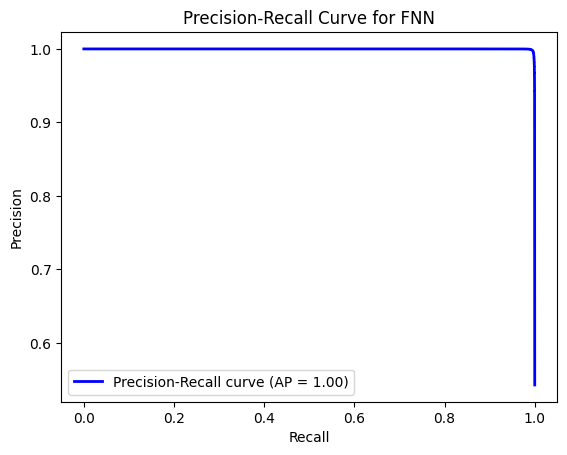

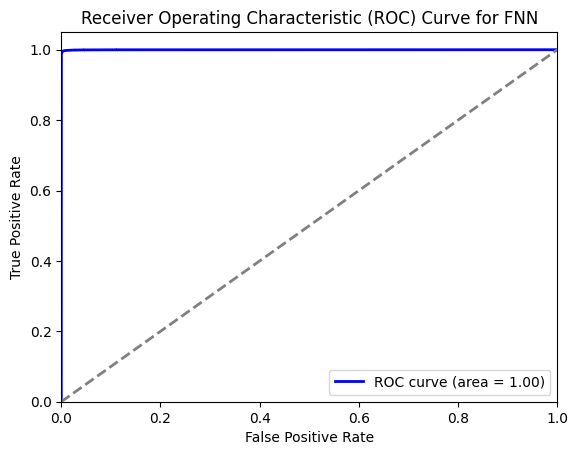

In [20]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(fnn_recall_vals, fnn_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {fnn_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for FNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(fnn_fpr, fnn_tpr, color='blue', lw=2, label=f'ROC curve (area = {fnn_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for FNN')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[140627    253]
 [  1018 166177]]


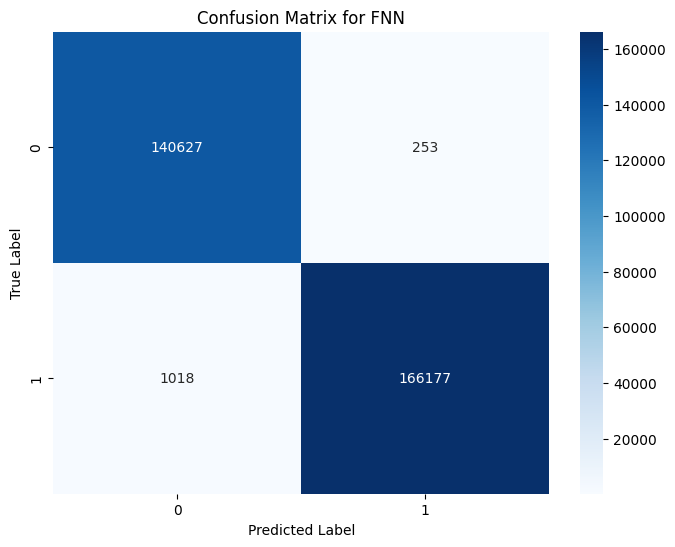

Classification report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00    140880
           1       1.00      0.99      1.00    167195

    accuracy                           1.00    308075
   macro avg       1.00      1.00      1.00    308075
weighted avg       1.00      1.00      1.00    308075



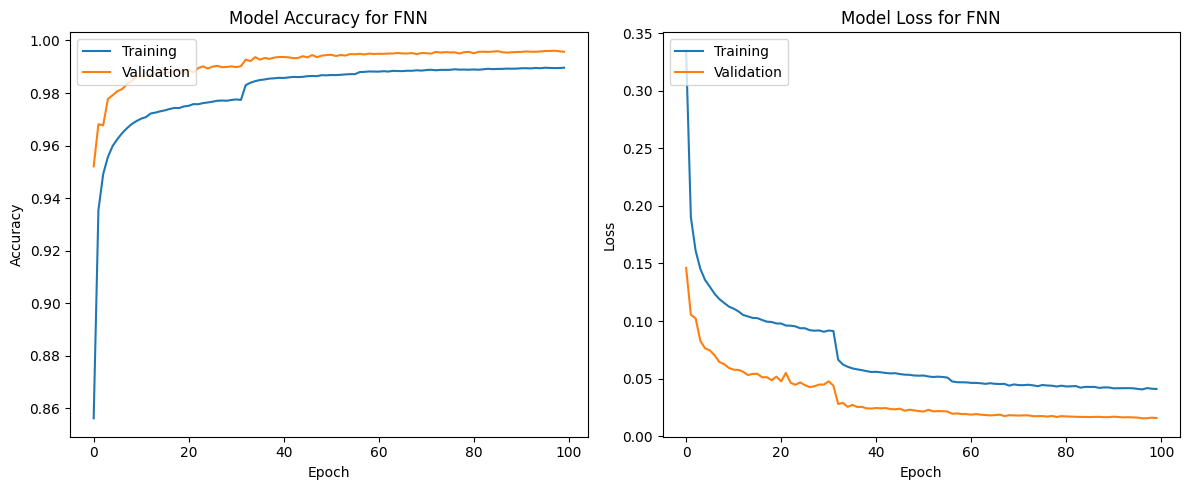

In [21]:
print("Confusion Matrix:")
print(fnn_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(fnn_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for FNN')
plt.show()

print("Classification report:")
print(fnn_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for FNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for FNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(fnn_history)

## CNN

In [22]:
print("CNN model:")
print("Accuracy: ", cnn_accuracy)
print("Precision: ", cnn_precision)
print("Recall: ", cnn_recall)
print("F1 score: ", cnn_f1)
print("Specificity: ", cnn_specificity)
print("AUC-ROC:", cnn_roc_auc)

CNN model:
Accuracy:  0.8214623062565933
Precision:  0.9197231575009353
Recall:  0.7351954304853614
F1 score:  0.8171716332330602
Specificity:  0.923842986939239
AUC-ROC: 0.916793562447926


In [23]:
print("cnn_avg_precision: ", cnn_avg_precision)
print("cnn_fpr: ", cnn_fpr)
print("cnn_tpr: ", cnn_tpr)
print("cnn_thresholds: ", cnn_thresholds)
print("cnn_precision_vals: ", cnn_precision_vals)
print("cnn_recall_vals: ", cnn_recall_vals)
print("cnn_pr_thresholds: ", cnn_pr_thresholds)

cnn_avg_precision:  0.9387151940330538
cnn_fpr:  [0.         0.         0.         ... 0.99509512 0.99510931 1.        ]
cnn_tpr:  [0.         0.4109453  0.41203983 ... 1.         1.         1.        ]
cnn_thresholds:  [       inf 1.         0.99999994 ... 0.00913774 0.00913675 0.00481168]
cnn_precision_vals:  [0.54270876 0.54271052 0.54271228 ... 1.         1.         1.        ]
cnn_recall_vals:  [1.         1.         1.         ... 0.41203983 0.4109453  0.        ]
cnn_pr_thresholds:  [0.00481168 0.00483161 0.00484989 ... 0.9999999  0.99999994 1.        ]


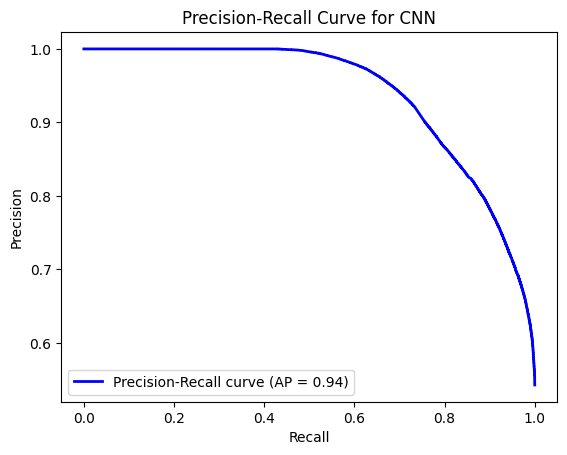

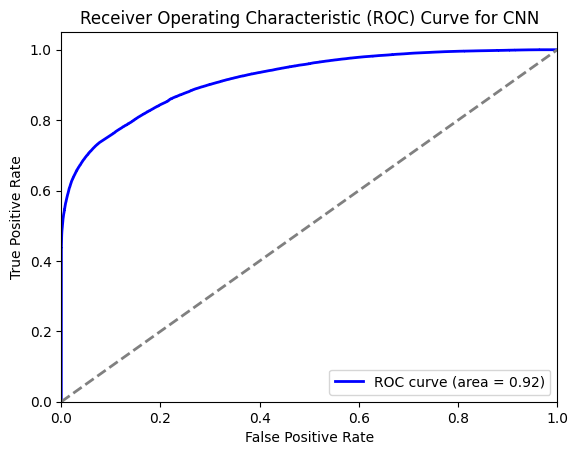

In [24]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(cnn_recall_vals, cnn_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {cnn_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for CNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(cnn_fpr, cnn_tpr, color='blue', lw=2, label=f'ROC curve (area = {cnn_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for CNN')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[130151  10729]
 [ 44274 122921]]


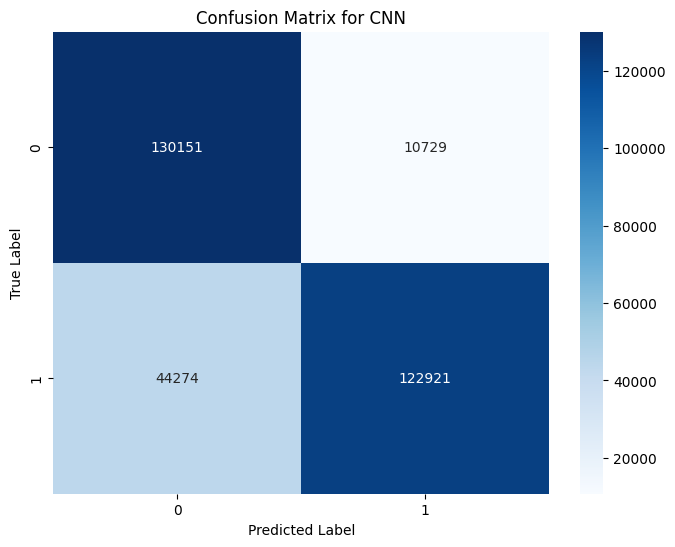

Classification report:
              precision    recall  f1-score   support

           0       0.75      0.92      0.83    140880
           1       0.92      0.74      0.82    167195

    accuracy                           0.82    308075
   macro avg       0.83      0.83      0.82    308075
weighted avg       0.84      0.82      0.82    308075



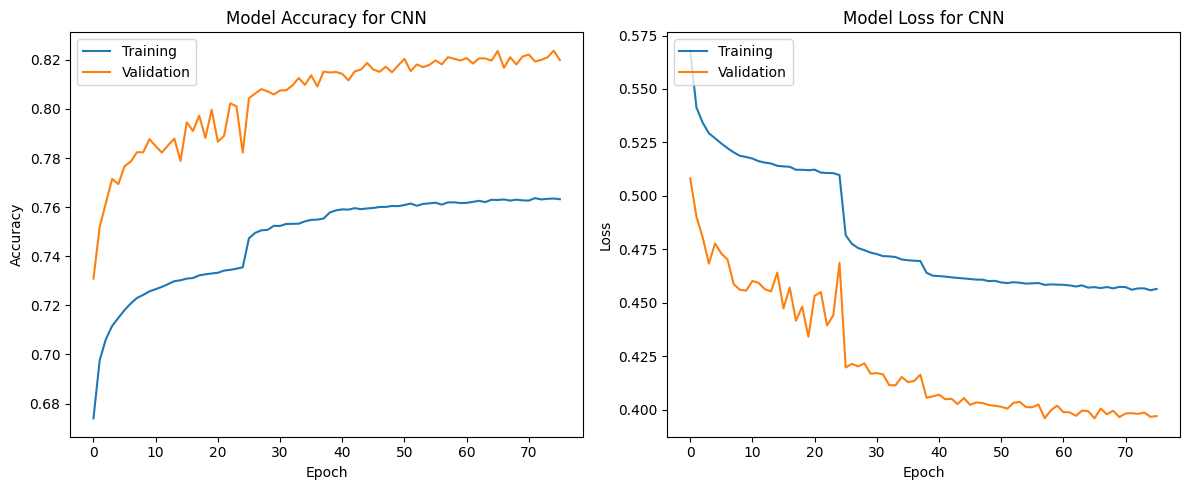

In [25]:
print("Confusion Matrix:")
print(cnn_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(cnn_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for CNN')
plt.show()

print("Classification report:")
print(cnn_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(cnn_history)

## LSTM

In [26]:
print("LSTM model:")
print("Accuracy: ", lstm_accuracy)
print("Precision: ", lstm_precision)
print("Recall: ", lstm_recall)
print("F1 score: ", lstm_f1)
print("Specificity: ", lstm_specificity)
print("AUC-ROC:", lstm_roc_auc)

LSTM model:
Accuracy:  0.9961859936703725
Precision:  0.9955761722248092
Recall:  0.9974042285953527
F1 score:  0.9964893620199763
Specificity:  0.9947402044293016
AUC-ROC: 0.9999476111960179


In [27]:
print("lstm_avg_precision: ", lstm_avg_precision)
print("lstm_fpr: ", lstm_fpr)
print("lstm_tpr: ", lstm_tpr)
print("lstm_thresholds: ", lstm_thresholds)
print("lstm_precision_vals: ", lstm_precision_vals)
print("lstm_recall_vals: ", lstm_recall_vals)
print("lstm_pr_thresholds: ", lstm_pr_thresholds)

lstm_avg_precision:  0.9999562456467076
lstm_fpr:  [0.         0.         0.         ... 0.99977995 0.99979415 1.        ]
lstm_tpr:  [0.         0.00196178 0.01062233 ... 1.         1.         1.        ]
lstm_thresholds:  [          inf 9.9999386e-01 9.9999380e-01 ... 8.8333300e-06 8.8330016e-06
 8.8170445e-06]
lstm_precision_vals:  [0.54270876 0.54271052 0.54271228 ... 1.         1.         1.        ]
lstm_recall_vals:  [1.         1.         1.         ... 0.01062233 0.00196178 0.        ]
lstm_pr_thresholds:  [8.8170445e-06 8.8197694e-06 8.8209217e-06 ... 9.9999374e-01 9.9999380e-01
 9.9999386e-01]


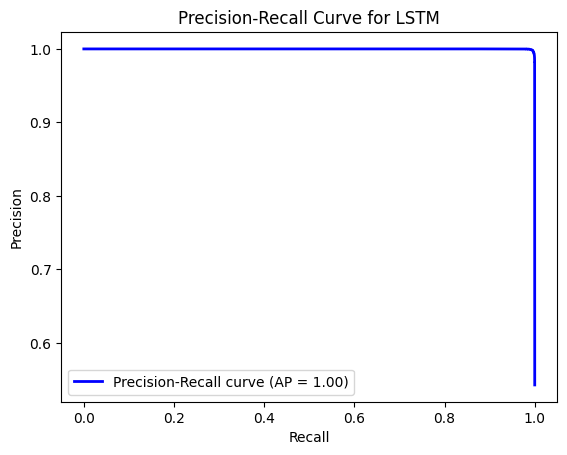

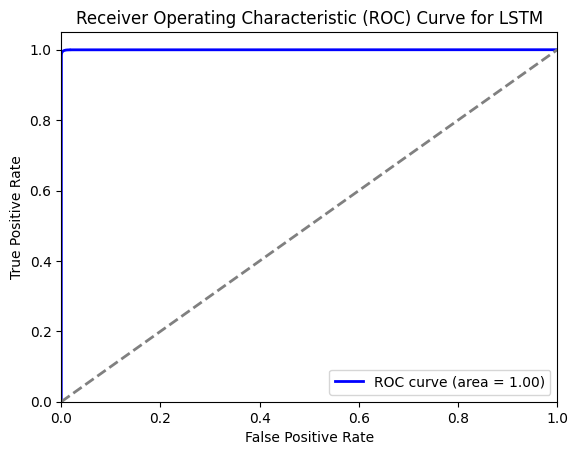

In [28]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(lstm_recall_vals, lstm_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {lstm_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for LSTM')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(lstm_fpr, lstm_tpr, color='blue', lw=2, label=f'ROC curve (area = {lstm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for LSTM')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[140139    741]
 [   434 166761]]


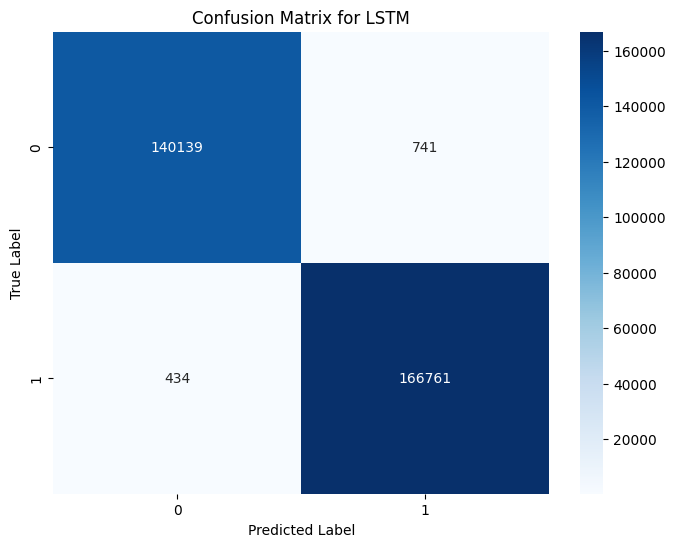

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    140880
           1       1.00      1.00      1.00    167195

    accuracy                           1.00    308075
   macro avg       1.00      1.00      1.00    308075
weighted avg       1.00      1.00      1.00    308075



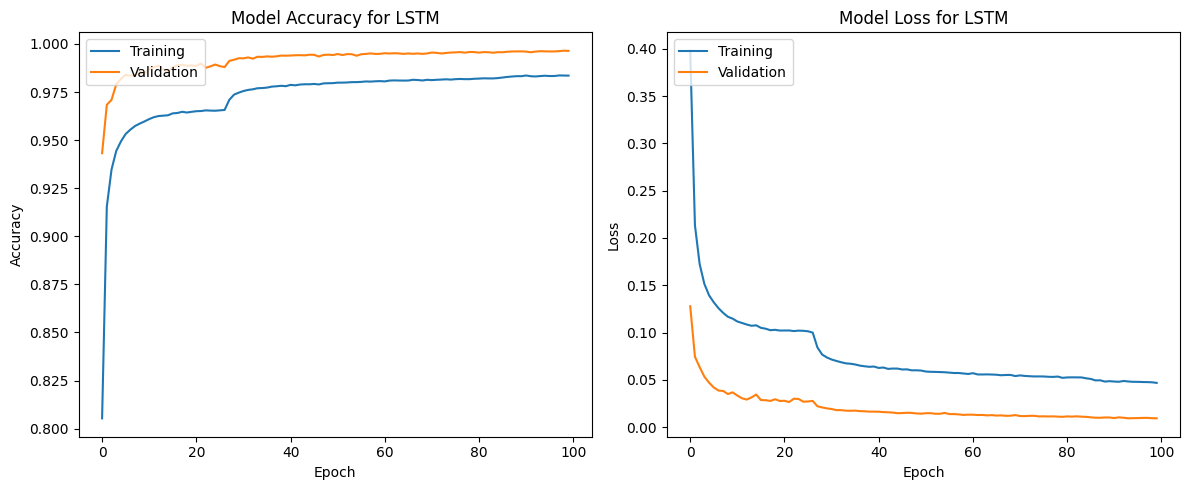

In [29]:
print("Confusion Matrix:")
print(lstm_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(lstm_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for LSTM')
plt.show()

print("Classification report:")
print(lstm_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for LSTM')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for LSTM')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(lstm_history)

## Combined

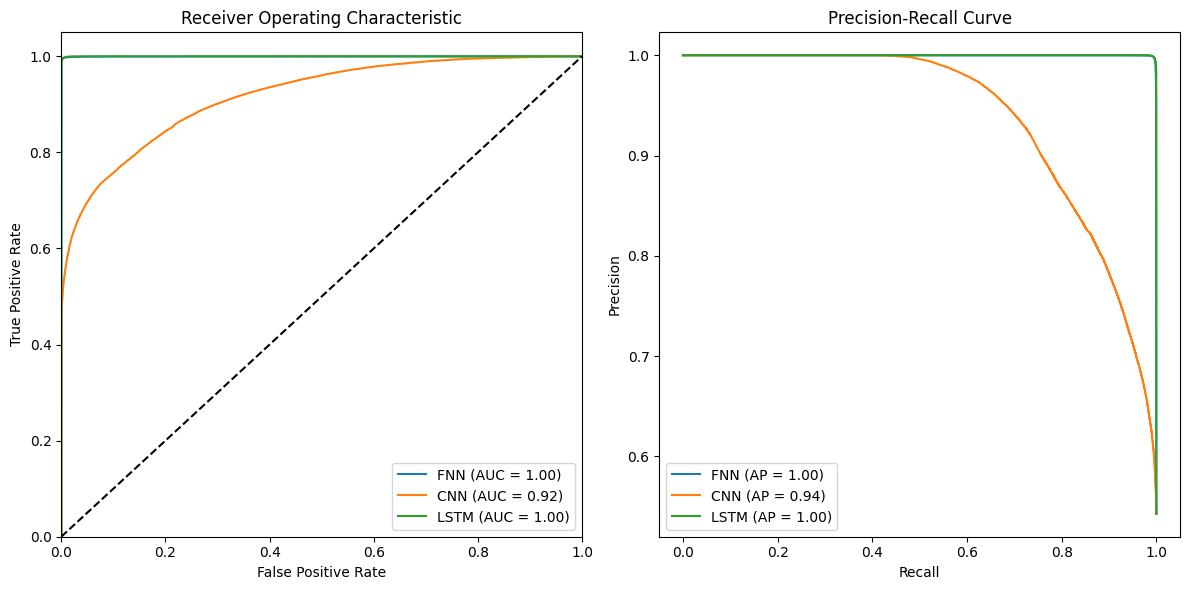

In [30]:
# Plot ROC curves
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(fnn_fpr, fnn_tpr, label=f'FNN (AUC = {fnn_roc_auc:.2f})')
plt.plot(cnn_fpr, cnn_tpr, label=f'CNN (AUC = {cnn_roc_auc:.2f})')
plt.plot(lstm_fpr, lstm_tpr, label=f'LSTM (AUC = {lstm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")

# Plot Precision-Recall curves
plt.subplot(1, 2, 2)
plt.plot(fnn_recall_vals, fnn_precision_vals, label=f'FNN (AP = {fnn_avg_precision:.2f})')
plt.plot(cnn_recall_vals, cnn_precision_vals, label=f'CNN (AP = {cnn_avg_precision:.2f})')
plt.plot(lstm_recall_vals, lstm_precision_vals, label=f'LSTM (AP = {lstm_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()

In [31]:
#%%shell
#jupyter nbconvert --to html /content/stress_detection_3secs.ipynb